# 01_cuDF / 01 — cuDF basics

**cuDF** is a GPU DataFrame library with a pandas-like API. Data lives in GPU memory (in Apache Arrow columnar format), and operations run as CUDA kernels.

This notebook covers:
1. Environment check (GPU, versions)
2. `Series` and `DataFrame` — creating, selecting, moving between pandas and cuDF
3. dtypes — numeric, strings, categoricals, datetimes, lists, structs, and **nulls**
4. IO — CSV and Parquet, with a first pandas vs cuDF timing
5. GPU memory — how much a DataFrame uses and how to free it

**Hardware:** NVIDIA T4 (16 GB). Works on Google Colab / Kaggle T4 runtimes.

## 1. Environment check

In [1]:
# Install cuDF only if it is missing (Colab GPU runtimes usually ship it already).
# If this installs something, restart the kernel before continuing.
import importlib.util, subprocess, sys

if importlib.util.find_spec("cudf") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "cudf-cu12", "--extra-index-url=https://pypi.nvidia.com"])
    print("cuDF installed: restart the kernel now.")
else:
    print("cuDF already installed.")

cuDF already installed.


In [2]:
!nvidia-smi

Thu Oct 29 07:31:26 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   57C    P0             28W /   70W |     115MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
import platform
import cudf, cupy as cp, numpy as np, pandas as pd

props = cp.cuda.runtime.getDeviceProperties(0)
free_b, total_b = cp.cuda.runtime.memGetInfo()

print(f"Python  : {platform.python_version()}")
print(f"cuDF    : {cudf.__version__}")
print(f"CuPy    : {cp.__version__}")
print(f"pandas  : {pd.__version__}")
print(f"NumPy   : {np.__version__}")
print(f"GPU     : {props['name'].decode()}  (compute capability {props['major']}.{props['minor']})")
print(f"GPU mem : {free_b / 1e9:.1f} GB free of {total_b / 1e9:.1f} GB")

Python  : 3.13.16
cuDF    : 26.06.00
CuPy    : 14.0.1
pandas  : 2.2.3
NumPy   : 2.1.3
GPU     : Tesla T4  (compute capability 7.5)
GPU mem : 15.4 GB free of 15.6 GB


### A small timing helper

GPU work is **asynchronous**: Python can get control back before the kernel has finished. To time GPU code correctly, we synchronize the device before stopping the clock, run a warmup first (the first call pays for kernel compilation and memory allocation), and take the median of several runs.

In [4]:
import time, statistics

def gpu_sync():
    cp.cuda.Device().synchronize()

def timeit(fn, repeats=5, warmup=1):
    """Median wall time in seconds, with GPU synchronized before each stop."""
    for _ in range(warmup):
        fn(); gpu_sync()
    times = []
    for _ in range(repeats):
        gpu_sync()
        t0 = time.perf_counter()
        fn()
        gpu_sync()
        times.append(time.perf_counter() - t0)
    return statistics.median(times)

## 2. Series and DataFrame

The API mirrors pandas: most code only needs `pd.` swapped for `cudf.`.

In [5]:
s = cudf.Series([10, 20, 30, None, 50], name="values")
s

0      10
1      20
2      30
3    <NA>
4      50
Name: values, dtype: int64

In [6]:
print("sum  :", s.sum())       # nulls are skipped
print("mean :", s.mean())
print("nulls:", s.isna().sum())
s * 2 + 1

sum  : 110
mean : 27.5
nulls: 1


0      21
1      41
2      61
3    <NA>
4     101
Name: values, dtype: int64

In [7]:
gdf = cudf.DataFrame({
    "id":    [1, 2, 3, 4, 5, 6],
    "city":  ["Hyderabad", "Pune", "Jaipur", "Pune", "Hyderabad", "Jaipur"],
    "sales": [120.5, 98.0, 143.2, 87.1, 160.0, 110.4],
    "units": [12, 9, 15, 8, 17, 11],
})
gdf

,id,city,sales,units
0,1,Hyderabad,120.5,12
1,2,Pune,98.0,9
2,3,Jaipur,143.2,15
3,4,Pune,87.1,8
4,5,Hyderabad,160.0,17
5,6,Jaipur,110.4,11


In [8]:
print(type(gdf))
gdf.info()

<class 'cudf.core.dataframe.DataFrame'>
<class 'cudf.core.dataframe.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   id      6 non-null      int64
 1   city    6 non-null      object
 2   sales   6 non-null      float64
 3   units   6 non-null      int64
dtypes: float64(1), int64(2), object(1)
memory usage: 210.0+ bytes


### Selecting rows and columns

In [9]:
gdf[["city", "sales"]].head(3)

,city,sales
0,Hyderabad,120.5
1,Pune,98.0
2,Jaipur,143.2


In [10]:
gdf.loc[gdf["sales"] > 100, ["id", "city", "sales"]]

,id,city,sales
0,1,Hyderabad,120.5
2,3,Jaipur,143.2
4,5,Hyderabad,160.0
5,6,Jaipur,110.4


In [11]:
gdf.iloc[1:4]

,id,city,sales,units
1,2,Pune,98.0,9
2,3,Jaipur,143.2,15
3,4,Pune,87.1,8


In [12]:
# query() only works on numeric, datetime, timedelta and bool columns
gdf.query("units >= 10 and sales > 115")

,id,city,sales,units
0,1,Hyderabad,120.5,12
2,3,Jaipur,143.2,15
4,5,Hyderabad,160.0,17


In [13]:
# For string columns, use a boolean mask instead (combine conditions with & and |)
gdf[(gdf["units"] >= 10) & (gdf["city"] == "Hyderabad")]

,id,city,sales,units
0,1,Hyderabad,120.5,12
4,5,Hyderabad,160.0,17


In [14]:
# New columns, sorting, simple aggregation
gdf["price_per_unit"] = gdf["sales"] / gdf["units"]
gdf.sort_values("price_per_unit", ascending=False)

,id,city,sales,units,price_per_unit
1,2,Pune,98.0,9,10.888889
3,4,Pune,87.1,8,10.887500
0,1,Hyderabad,120.5,12,10.041667
5,6,Jaipur,110.4,11,10.036364
2,3,Jaipur,143.2,15,9.546667
4,5,Hyderabad,160.0,17,9.411765


In [15]:
gdf.describe()

,id,sales,units,price_per_unit
count,6.000000,6.000000,6.000000,6.000000
mean,3.500000,119.866667,12.000000,10.135475
std,1.870829,27.557044,3.464102,0.635964
min,1.000000,87.100000,8.000000,9.411765
25%,2.250000,101.100000,9.500000,9.669091
50%,3.500000,115.450000,11.500000,10.039015
75%,4.750000,137.525000,14.250000,10.676042
max,6.000000,160.000000,17.000000,10.888889


### Moving between pandas, cuDF and CuPy

Every conversion copies data between host (CPU) RAM and GPU memory over PCIe. That copy is often the slowest step, so keep data on the GPU for as long as possible.

In [16]:
pdf = gdf.to_pandas()              # GPU -> CPU
print(type(pdf))

gdf2 = cudf.from_pandas(pdf)       # CPU -> GPU
print(type(gdf2))

arr = gdf[["sales", "units"]].to_cupy()   # stays on the GPU, zero CPU copies
print(type(arr), arr.shape, arr.dtype)

<class 'pandas.core.frame.DataFrame'>
<class 'cudf.core.dataframe.DataFrame'>
<class 'cupy.ndarray'> (6, 2) float64


## 3. dtypes

cuDF uses **Arrow-style nulls**: every column can hold `<NA>`, including ints and strings. pandas traditionally uses `NaN` for missing values, which forces int columns to float. This is one of the most common differences you will see.

In [17]:
# Integers with a missing value: pandas upcasts to float64, cuDF keeps int64 + null
p_int = pd.Series([1, 2, None])
g_int = cudf.Series([1, 2, None])
print("pandas:", p_int.dtype, list(p_int))
print("cuDF  :", g_int.dtype, g_int.to_arrow().to_pylist())

pandas: float64 [1.0, 2.0, nan]
cuDF  : int64 [1, 2, None]


In [ ]:
# NaN and null are different things in cuDF: NaN is a float *value*, null means "missing".
# Building a Series from data that contains NaN usually converts NaN -> null, so we create
# a real NaN with arithmetic instead: 0.0 / 0.0 = NaN.
g_float = cudf.Series([0.0, 1.0, 3.0]) / cudf.Series([0.0, 1.0, 1.0])
print(g_float.to_arrow().to_pylist())
print("null_count             :", g_float.null_count)
print("after nans_to_nulls()  :", g_float.nans_to_nulls().null_count)

### Strings

In [21]:
names = cudf.Series(["  Alice ", "bob", None, "CHARLIE", "dave_smith"])
cudf.DataFrame({
    "raw":      names,
    "clean":    names.str.strip().str.lower(),
    "length":   names.str.len(),
    "has_a":    names.str.contains("a", regex=False),
    "first":    names.str.split("_").list.get(0),
})

,raw,clean,length,has_a,first
0,Alice,alice,8,False,Alice
1,bob,bob,3,False,bob
2,None,None,<NA>,<NA>,None
3,CHARLIE,charlie,7,False,CHARLIE
4,dave_smith,dave_smith,10,True,dave


### Categoricals

In [22]:
cities = gdf["city"].astype("category")
print("categories:", cities.cat.categories.to_pandas().tolist())
print("codes     :", cities.cat.codes.to_pandas().tolist())
print("memory (string)  :", gdf["city"].memory_usage(), "bytes")
print("memory (category):", cities.memory_usage(), "bytes")

categories: ['Hyderabad', 'Jaipur', 'Pune']
codes     : [0, 2, 1, 2, 0, 1]
memory (string)  : 66 bytes
memory (category): 41 bytes


### Datetimes

In [23]:
ts = cudf.Series(pd.date_range("2026-01-01", periods=6, freq="17D"))
cudf.DataFrame({
    "ts":      ts,
    "year":    ts.dt.year,
    "month":   ts.dt.month,
    "weekday": ts.dt.weekday,
    "plus_1d": ts + pd.Timedelta(days=1),
})

,ts,year,month,weekday,plus_1d
0,2026-01-01,2026,1,3,2026-01-02
1,2026-01-18,2026,1,6,2026-01-19
2,2026-02-04,2026,2,2,2026-02-05
3,2026-02-21,2026,2,5,2026-02-22
4,2026-03-10,2026,3,1,2026-03-11
5,2026-03-27,2026,3,4,2026-03-28


### Nested types: lists and structs

Arrow supports nested columns natively, so cuDF can hold a list or a dict in every row, all on the GPU.

In [24]:
tags = cudf.Series([["gpu", "rapids"], ["cuda"], None, ["pandas", "arrow", "parquet"]])
print(tags.dtype)
cudf.DataFrame({"tags": tags, "n_tags": tags.list.len(), "first": tags.list.get(0)})

list


,tags,n_tags,first
0,"[gpu, rapids]",2,gpu
1,[cuda],1,cuda
2,None,<NA>,None
3,"[pandas, arrow, parquet]",3,pandas


In [25]:
people = cudf.Series([{"name": "Asha", "age": 31}, {"name": "Ravi", "age": 27}, None])
print(people.dtype)
cudf.DataFrame({"name": people.struct.field("name"), "age": people.struct.field("age")})

struct


,name,age
0,Asha,31
1,Ravi,27
2,None,<NA>


### Casting

In [26]:
mixed = cudf.DataFrame({"a": ["1", "2", "3"], "b": [1.7, 2.2, 3.9]})
mixed["a"] = mixed["a"].astype("int32")
mixed["b"] = mixed["b"].astype("int16")      # truncates toward zero
mixed.dtypes

,0
a,int32
b,int16


## 4. IO: CSV and Parquet

We generate a synthetic table, write it to disk, then read it back with pandas and with cuDF.

- **CSV** is text: every value has to be parsed. cuDF parses in parallel on the GPU.
- **Parquet** is columnar and compressed, and cuDF decodes it directly on the GPU. It is the preferred format for GPU work.

`N_ROWS` is sized for a T4. Increase it to see the gap grow.

In [27]:
import os

N_ROWS = 5_000_000
DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)

rng = cp.random.default_rng(42)
big = cudf.DataFrame({
    "user_id":  rng.integers(0, 1_000_000, N_ROWS),
    "amount":   rng.random(N_ROWS) * 1000,
    "quantity": rng.integers(1, 20, N_ROWS).astype("int32"),
    "category": cudf.Series([f"cat_{i}" for i in range(50)])
                    .take(rng.integers(0, 50, N_ROWS)).reset_index(drop=True),
})
print(f"{len(big):,} rows")
big.head()

5,000,000 rows


,user_id,amount,quantity,category
0,163071,772.484381,6,cat_46
1,147572,233.419928,11,cat_7
2,996619,30.497503,4,cat_39
3,833159,447.073743,6,cat_20
4,817642,591.959303,7,cat_35


In [28]:
csv_path = os.path.join(DATA_DIR, "transactions.csv")
pq_path  = os.path.join(DATA_DIR, "transactions.parquet")

t_csv = timeit(lambda: big.to_csv(csv_path, index=False), repeats=1, warmup=0)
t_pq  = timeit(lambda: big.to_parquet(pq_path), repeats=1, warmup=0)
print(f"cuDF write CSV     : {t_csv:.2f} s  ({os.path.getsize(csv_path) / 1e6:.0f} MB)")
print(f"cuDF write Parquet : {t_pq:.2f} s  ({os.path.getsize(pq_path) / 1e6:.0f} MB)")

cuDF write CSV     : 0.31 s  (141 MB)
cuDF write Parquet : 0.26 s  (72 MB)


In [29]:
results = {
    ("CSV", "pandas"):     timeit(lambda: pd.read_csv(csv_path), repeats=3),
    ("CSV", "cuDF"):       timeit(lambda: cudf.read_csv(csv_path), repeats=3),
    ("Parquet", "pandas"): timeit(lambda: pd.read_parquet(pq_path), repeats=3),
    ("Parquet", "cuDF"):   timeit(lambda: cudf.read_parquet(pq_path), repeats=3),
}

read_times = pd.Series(results).unstack()
read_times["speedup"] = read_times["pandas"] / read_times["cuDF"]
read_times.round(3)

,cuDF,pandas,speedup
CSV,0.113,1.753,15.547
Parquet,0.037,0.427,11.649


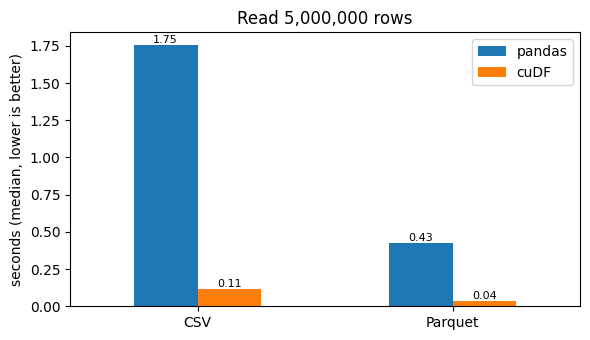

In [30]:
import matplotlib.pyplot as plt

ax = read_times[["pandas", "cuDF"]].plot.bar(rot=0, figsize=(6, 3.5))
ax.set_ylabel("seconds (median, lower is better)")
ax.set_title(f"Read {N_ROWS:,} rows")
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=8)
plt.tight_layout()
plt.show()

In [31]:
# Read only what you need: column projection skips the other columns entirely
cols = cudf.read_parquet(pq_path, columns=["user_id", "amount"])
cols.dtypes

,0
user_id,int64
amount,float64


## 5. GPU memory

A T4 has 16 GB. A useful rule of thumb is that a workflow needs **2–3× the size of the data** in GPU memory, because many operations make temporary copies.

In [32]:
def gpu_mem(label=""):
    free_b, total_b = cp.cuda.runtime.memGetInfo()
    print(f"{label:<28} used {(total_b - free_b) / 1e9:5.2f} GB / {total_b / 1e9:.1f} GB")

gpu_mem("now")

now                          used  0.50 GB / 15.6 GB


In [33]:
usage = big.memory_usage(deep=True).to_pandas()
print((usage / 1e6).round(1).astype(str) + " MB")
print(f"total: {usage.sum() / 1e6:.0f} MB")

Index        0.0 MB
user_id     40.0 MB
amount      40.0 MB
quantity    20.0 MB
category    49.0 MB
dtype: object
total: 149 MB


In [34]:
# Strings are stored as one big character buffer + offsets; categoricals store small int codes
before = big["category"].memory_usage()
big["category"] = big["category"].astype("category")
after = big["category"].memory_usage()
print(f"category column: {before / 1e6:.0f} MB -> {after / 1e6:.0f} MB")

category column: 49 MB -> 5 MB


In [35]:
# Downcasting numeric columns also saves memory
before = big.memory_usage(deep=True).sum()
big["user_id"] = big["user_id"].astype("int32")
big["amount"]  = big["amount"].astype("float32")
after = big.memory_usage(deep=True).sum()
print(f"whole frame: {before / 1e6:.0f} MB -> {after / 1e6:.0f} MB")

whole frame: 105 MB -> 65 MB


In [36]:
# Freeing memory: drop every reference, then let Python collect it
import gc

gpu_mem("before del")
del big, cols
gc.collect()
gpu_mem("after del + gc.collect()")

before del                   used  0.55 GB / 15.6 GB
after del + gc.collect()     used  0.41 GB / 15.6 GB


Memory used never drops back to zero:

- The **CUDA context** itself takes a few hundred MB as soon as the GPU is first used.
- cuDF/RMM and CuPy may **cache** freed blocks to reuse them for the next allocation instead of returning them to the driver.

So "used" in `nvidia-smi` or `memGetInfo` is an upper bound, not the size of your live DataFrames.

## 6. Host ↔ device transfer cost

Copying data between CPU and GPU goes over PCIe. On small or simple workloads this copy can cost more than the computation saves.

In [37]:
pdf_big = pd.read_parquet(pq_path)

t_h2d = timeit(lambda: cudf.from_pandas(pdf_big), repeats=3)
gdf_big = cudf.from_pandas(pdf_big)
t_d2h = timeit(lambda: gdf_big.to_pandas(), repeats=3)
t_sum_gpu = timeit(lambda: gdf_big["amount"].sum(), repeats=5)
t_sum_cpu = timeit(lambda: pdf_big["amount"].sum(), repeats=5)

print(f"CPU -> GPU copy : {t_h2d * 1e3:8.1f} ms")
print(f"GPU -> CPU copy : {t_d2h * 1e3:8.1f} ms")
print(f"sum on GPU      : {t_sum_gpu * 1e3:8.2f} ms")
print(f"sum on CPU      : {t_sum_cpu * 1e3:8.2f} ms")

CPU -> GPU copy :    370.1 ms
GPU -> CPU copy :    639.1 ms
sum on GPU      :     0.80 ms
sum on CPU      :     6.13 ms


A single `sum()` is far cheaper than copying the data to the GPU. The GPU pays off when you load directly onto it (e.g. `cudf.read_parquet`) and run **many** operations before bringing a small result back.

In [38]:
del pdf_big, gdf_big
gc.collect()
gpu_mem("end of notebook")

end of notebook              used  0.41 GB / 15.6 GB


## Summary

- cuDF mirrors the pandas API: `cudf.DataFrame`, `.loc`, `.query`, `.sort_values`, `.describe`, `.str`, `.dt`.
- Every column is nullable (`<NA>`); ints stay ints when values are missing. NaN (a float value) and null (missing) are separate; use `.nans_to_nulls()` to unify them.
- Nested `list` and `struct` columns are first-class.
- Prefer **Parquet** and read only the columns you need.
- Measure GPU time with a sync and a warmup.
- Keep data on the GPU: PCIe copies are expensive compared to most single operations.
- Use categoricals and smaller numeric dtypes to fit more data on a 16 GB T4.

**Try it:** raise `N_ROWS` to 20M and rerun section 4. Where does pandas start to struggle?

**Next:** `02_cudf_operations.ipynb` — groupby, joins, sorting, string ops and window functions.